In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Read in all diel data

In [102]:
import geopandas as gpd 
from shapely.geometry import Point

timeres = '30min'

diel_pi = pd.read_csv('../data/all_pops_diel_pi_30min.csv')
params = ['Pmax_obs', 'alpha_obs', 'beta_obs', 'Ek_obs']

# reformat wide to long
diel_pi_long = diel_pi.melt(id_vars = ['index_id', 'cruise', 'cruise_day', 'pop'],
             value_vars = params,
             var_name = 'parameter',
             value_name = 'estimate')
# pair with longhurst data
## read in cleaned df with lat/lon information
hot_cruise_smooth = pd.read_pickle('../data/smoothed_par_data/hot_cruise_smooth_30min.pickle')
# set lon range between -180 to 180
# hot_cruise_smooth['lon'] = np.where(hot_cruise_smooth['lon']>180, hot_cruise_smooth['lon']-360)
coords_info = hot_cruise_smooth.groupby(['cruise', 'cruise_day']).agg({
    'lat': 'mean', 
    'lon': 'mean'
}).reset_index()


lh_shapefile = '../../../seaflow/seaflow_tsd_project/data/shapefiles/Longhurst_world_v4_2010/Longhurst_world_v4_2010.shp'
gfinal_rates = gpd.read_file(lh_shapefile)
gfinal_rates['biome'] = gfinal_rates['ProvDescr'].str.split().str[0]

# Convert dataframe to a GeoDataFrame
coords_info['geometry'] = coords_info.apply(lambda row: Point(row['lon'], row['lat']), axis=1)
coords_info_geo = gpd.GeoDataFrame(coords_info, geometry='geometry', crs=gfinal_rates.crs)

# Perform spatial join to get region information
coords_info_geo = gpd.sjoin(coords_info_geo, gfinal_rates[['geometry', 'ProvCode', 'biome']], how='left', predicate='within')

coords_info_geo.rename(columns={'ProvCode': 'region'}, inplace=True)
# Manual Fix: columns with nan are in hawaii (NPTG TRADES)
coords_info_geo.loc[coords_info_geo['region'].isna(), 'region'] = 'NPTG'
coords_info_geo.loc[coords_info_geo['biome'].isna(), 'biome'] = 'Trades'

# Save the updated dataframe
coords_info_geo.drop(columns=['geometry', 'index_right'], inplace=True)
# merge with pi data
pi_merged = diel_pi_long.merge(coords_info_geo)

<>:1: SyntaxWarning: invalid escape sequence '\m'
<>:2: SyntaxWarning: invalid escape sequence '\m'
<>:3: SyntaxWarning: invalid escape sequence '\m'
<>:1: SyntaxWarning: invalid escape sequence '\m'
<>:2: SyntaxWarning: invalid escape sequence '\m'
<>:3: SyntaxWarning: invalid escape sequence '\m'
/var/folders/x3/sy2cc75s04157vygzwcwbbzr0000gn/T/ipykernel_61916/1599784282.py:1: SyntaxWarning: invalid escape sequence '\m'
  h1 = "$\mathregular{h^{-1}}$"
/var/folders/x3/sy2cc75s04157vygzwcwbbzr0000gn/T/ipykernel_61916/1599784282.py:2: SyntaxWarning: invalid escape sequence '\m'
  m2 = "$\mathregular{m^{-2}}$"
/var/folders/x3/sy2cc75s04157vygzwcwbbzr0000gn/T/ipykernel_61916/1599784282.py:3: SyntaxWarning: invalid escape sequence '\m'
  s1 = "$\mathregular{s^{-1}}$"


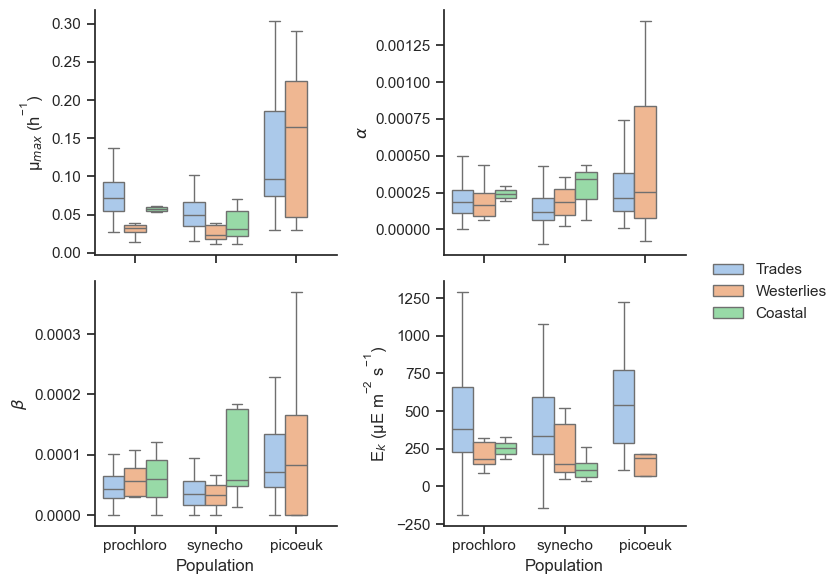

In [103]:
h1 = "$\mathregular{h^{-1}}$"
m2 = "$\mathregular{m^{-2}}$" 
s1 = "$\mathregular{s^{-1}}$"
# labels
# params = ['Pmax', 'alpha', 'beta', 'Ek']
param_labels = {
    'Pmax_obs':  'µ$_{max}$'+ f' ({h1})',
    'alpha_obs': r'$\alpha$',
    'beta_obs':  r'$\beta$',
    'Ek_obs':    f'E$_k$ (µE {m2} {s1})',
}
# set population order
pops = ['prochloro', 'synecho', 'picoeuk']

# create a facet plot
g = sns.FacetGrid(
    pi_merged,
    col="parameter",
    col_wrap=2,
    sharey=False,
    legend_out=True,
    aspect = 1.2
)
g.map_dataframe(
    sns.boxplot,
    x="pop",
    y="estimate",
    order=pops,
    hue="biome",
    showfliers=False,
    palette="pastel",
)
# Set the corresponding y-axis label for each parameter
for parameter, ax in g.axes_dict.items():
    ax.set_ylabel(param_labels.get(parameter, parameter))
    ax.set_xlabel("Population")

g.set_titles("")
g.add_legend()
g.tight_layout()

### Only look at diel cruise

<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
/var/folders/x3/sy2cc75s04157vygzwcwbbzr0000gn/T/ipykernel_61916/3112548392.py:4: SyntaxWarning: invalid escape sequence '\m'
  h1 = "$\mathregular{h^{-1}}$"
/var/folders/x3/sy2cc75s04157vygzwcwbbzr0000gn/T/ipykernel_61916/3112548392.py:5: SyntaxWarning: invalid escape sequence '\m'
  m2 = "$\mathregular{m^{-2}}$"
/var/folders/x3/sy2cc75s04157vygzwcwbbzr0000gn/T/ipykernel_61916/3112548392.py:6: SyntaxWarning: invalid escape sequence '\m'
  s1 = "$\mathregular{s^{-1}}$"


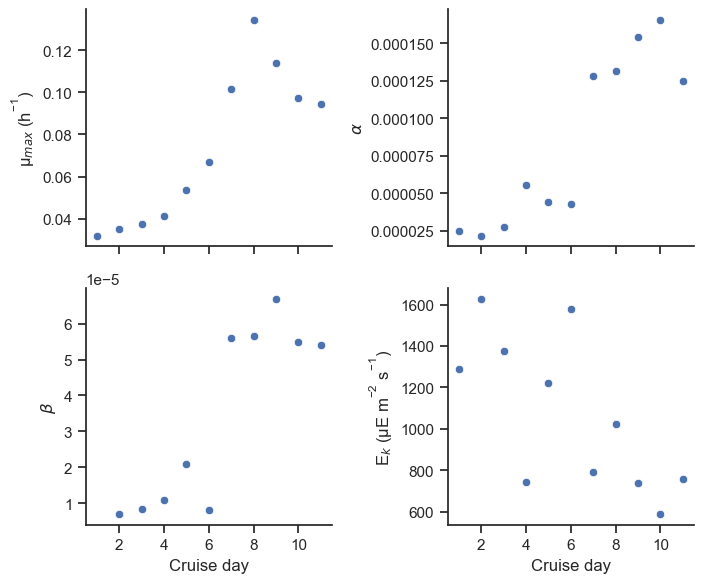

In [ ]:
diel_pro = diel_pi_long.loc[(diel_pi_long['cruise'] == 'KM1513') & 
                            (diel_pi_long['pop'] == 'prochloro')]

h1 = "$\mathregular{h^{-1}}$"
m2 = "$\mathregular{m^{-2}}$" 
s1 = "$\mathregular{s^{-1}}$"
# labels
params = ['Pmax_obs', 'alpha_obs', 'beta_obs', 'Ek_obs']
param_labels = {
    'Pmax_obs':  'µ$_{max}$'+ f' ({h1})',
    'alpha_obs': r'$\alpha$',
    'beta_obs':  r'$\beta$',
    'Ek_obs':    f'E$_k$ (µE {m2} {s1})',
}

from matplotlib.ticker import MaxNLocator
pops = ['prochloro']#, 'synecho', 'picoeuk']
colors = ['tab:blue']#, 'tab:orange', 'tab:green']
pop_palette = dict(zip(pops, colors))

custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

# plot changing PI parameters over TIME
g = sns.FacetGrid(
    diel_pro,
    col="parameter",
    col_order=params,
    col_wrap=2,
    sharey=False,
    sharex=True,
    height = 3,
    aspect = 1.2
)

g.map_dataframe(
    sns.scatterplot,
    x="cruise_day",
    y="estimate"
)

# Set a different y-axis label for each parameter facet.
for parameter, ax in g.axes_dict.items():
    ax.set_ylabel(param_labels.get(parameter, parameter))
    ax.set_xlabel("Cruise day")

for parameter, ax in g.axes_dict.items():
    ax.set_ylabel(param_labels.get(parameter, parameter))
    ax.set_xlabel("Cruise day")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))


g.set_titles("")
g.tight_layout()

/var/folders/x3/sy2cc75s04157vygzwcwbbzr0000gn/T/ipykernel_61916/1470603069.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  mld_df = pd.read_csv(


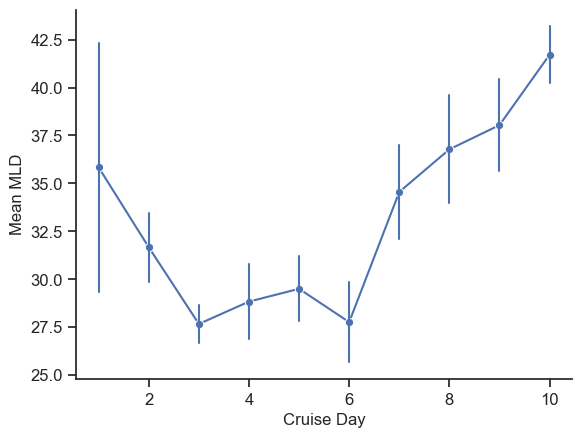

In [5]:
# Read in MLD Data
mld_path = '~/Desktop/UW/projects/pe_curves/data/km1513_mld_clean.txt'
mld_df = pd.read_csv(
    mld_path,
    delim_whitespace=True,   # treat any whitespace as the separator
    comment="#"              # optional, in case there are comment lines
)
# convert julian day to actual days
## Year corresponding to your julian days
year = 2015
# Convert julday (e.g. 206.84) to datetime in UTC
base = pd.Timestamp(f"{year}-01-01T00:00:00Z")
mld_df["datetime_utc"] = base + pd.to_timedelta(mld_df["julday"] - 1, unit="D")
# round to the nearest hour
mld_df["time"] = mld_df["datetime_utc"].dt.round(timeres)
# calculate the mean MLD across the 3 methods
mld_df['mean_MLD'] = (mld_df['MLD1'] + mld_df['MLD2'] + mld_df['MLD3']) / 3

# read in clean growth rate data
clean_growth = pd.read_csv(f'../data/all_smooth_diel_30min.csv')
# subset
cols = ['time', 'cruise_day']
diel_growth = clean_growth.loc[clean_growth['cruise'] == 'KM1513'].drop_duplicates(subset = ['time'])
# clean up time
diel_growth['time'] = pd.DatetimeIndex(diel_growth['time']).tz_convert('UTC')
diel_mld = mld_df[['time', 'mean_MLD']].merge(diel_growth[cols])
# groupby day
daily_mld = diel_mld.groupby(['cruise_day']).mean().reset_index()

# plot
fig, axs = plt.subplots()
sns.lineplot(x = diel_mld['cruise_day'], y = diel_mld['mean_MLD'], marker = 'o', errorbar= 'se', err_style='bars')
axs.set_xlabel('Cruise Day', fontsize = 12)
axs.set_ylabel('Mean MLD', fontsize = 12)
axs.tick_params(axis = 'both', labelsize = 12)

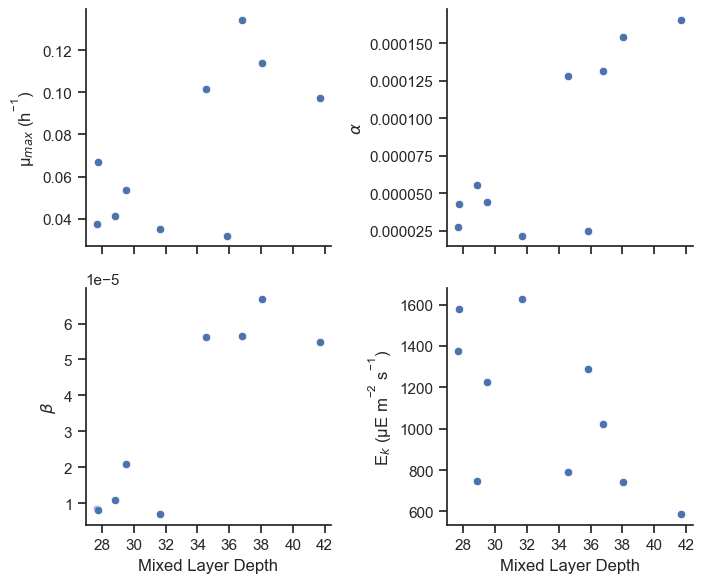

In [18]:
# merge mld and PI datasets
pi_mld = daily_mld.merge(diel_pro)

# plot over MLD
g = sns.FacetGrid(
    pi_mld,
    col="parameter",
    col_order=params,
    col_wrap=2,
    sharey=False,
    sharex=True,
    height = 3,
    aspect = 1.2
)

g.map_dataframe(
    sns.scatterplot,
    x="mean_MLD",
    y="estimate"
)

for parameter, ax in g.axes_dict.items():
    ax.set_ylabel(param_labels.get(parameter, parameter))
    ax.set_xlabel("Mixed Layer Depth")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))


g.set_titles("")
g.tight_layout()

### Recreating PI curves from Amirian model

In [ ]:
# helper fuctions to generate mohammad's PI curves

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def amirian_pi(I, alpha, Pmax, beta):
    """Amirian double-tanh PI model, with respiration fixed at zero."""
    I = np.asarray(I, dtype=float)
    gamma = np.cosh(1.0)**2

    ratio = np.full_like(I, np.inf)
    np.divide(
        Pmax,
        beta * I,
        out=ratio,
        where=(beta * I > 0)
    )

    saturation = np.tanh(alpha * I / Pmax)
    inhibition = np.tanh(np.minimum(ratio, 100.0)**gamma)

    return Pmax * saturation * inhibition


def reconstruct_daily_pi(df, n_grid=300):
    """
    Reconstruct one PI curve per index_id from wide-format parameters.

    Required columns
    ----------------
    index_id, alpha, Pmax, beta,
    cruise, cruise_day, pop, time_res,
    hour, I, P

    Returns
    -------
    daily_curves : DataFrame
        Smooth reconstructed curves, with daily metadata.
    daily_params : DataFrame
        One parameter set per index_id, including reconstruction status.
    observations : DataFrame
        Hourly I and P observations without repeated identical rows.
    """
    names = ["alpha", "Pmax", "beta"]

    metadata_cols = [
        "index_id", "cruise", "cruise_day", "pop", "time_res"
    ]

    required_cols = list(dict.fromkeys(
        metadata_cols + names + ["hour", "I", "P"]
    ))
    missing_cols = [col for col in required_cols if col not in df.columns]

    if missing_cols:
        raise ValueError(f"Missing required columns: {missing_cols}")

    # Remove copies of the same daily parameter set repeated across hours.
    parameter_rows = (
        df[["index_id"] + names]
        .drop_duplicates()
    )

    # Do not silently average conflicting parameter sets.
    if parameter_rows["index_id"].duplicated().any():
        raise ValueError(
            "Some index_id values have multiple distinct parameter sets. "
            "Check the grouping or add a draw identifier."
        )

    # Parameters are already in wide format; no pivot is needed.
    params = parameter_rows.set_index("index_id")[names]

    metadata = df[metadata_cols].drop_duplicates()

    if metadata["index_id"].duplicated().any():
        raise ValueError(
            "index_id does not uniquely identify the daily metadata."
        )

    observations = (
        df[["index_id", "hour", "I", "P"]]
        .drop_duplicates()
        .sort_values(["index_id", "hour"])
    )

    valid = (
        params.notna().all(axis=1)
        & np.isfinite(params).all(axis=1)
        & params["alpha"].ge(0)
        & params["Pmax"].gt(0)
        & params["beta"].ge(0)
    )

    curve_tables = []

    for index_id, pars in params.loc[valid].iterrows():
        I_max = observations.loc[
            observations["index_id"].eq(index_id), "I"
        ].max()

        if not np.isfinite(I_max) or I_max <= 0:
            continue

        I_grid = np.linspace(0, I_max, n_grid)

        curve_tables.append(
            pd.DataFrame({
                "index_id": index_id,
                "I": I_grid,
                "P_fit": amirian_pi(
                    I_grid,
                    alpha=pars["alpha"],
                    Pmax=pars["Pmax"],
                    beta=pars["beta"],
                ),
            })
        )

    daily_curves = (
        pd.concat(curve_tables, ignore_index=True)
        if curve_tables
        else pd.DataFrame(columns=["index_id", "I", "P_fit"])
    )

    daily_curves = daily_curves.merge(
        metadata,
        on="index_id",
        validate="many_to_one",
    )

    daily_params = params.reset_index().merge(
        metadata,
        on="index_id",
        validate="one_to_one",
    )

    reconstructed_ids = set(daily_curves["index_id"])

    daily_params["status"] = np.where(
        daily_params["index_id"].isin(reconstructed_ids),
        "reconstructed",
        "missing_or_invalid_parameters_or_irradiance",
    )

    return daily_curves, daily_params, observations

In [97]:
# read in pi label data
all_pi_labs = pd.read_csv('../data/all_pi_labels.csv')
# subset to just the cols we need 
all_pi_sub = all_pi_labs[['cruise', 'cruise_day', 'pop', 'index_id', 'time_res', 'hour', 'P', 'I']]

# merge wide diel PI params with P, I data
cols = ['index_id', 'cruise', 'cruise_day', 'pop', 'Pmax_fit', 'alpha_fit', 'beta_fit']
biome_diel_pi = diel_pi[cols].merge(coords_info_geo)
all_PI_df = all_pi_sub.merge(biome_diel_pi)

df = all_PI_df.copy()
# add a time resolution column
df['time_res'] = timeres
# rename cols to fit function
df.rename(columns = {
    'Pmax_fit': 'Pmax', 
    'alpha_fit': 'alpha',
    'beta_fit': 'beta'
}, inplace = True)

In [98]:
daily_curves, daily_params, observations = reconstruct_daily_pi(df)

# Inspect IDs that could not be reconstructed.
skipped = daily_params.loc[
    daily_params["status"] != "reconstructed"
]

# Add biome metadata, which was not included in the previous daily_params table.
metadata = df[["index_id", "biome", "pop"]].drop_duplicates()

if metadata["index_id"].duplicated().any():
    raise ValueError("Some index_id values have conflicting biome/pop metadata.")

# Keep only complete, valid daily parameter sets.
pars = (
    daily_params.loc[
        daily_params["status"].eq("reconstructed"),
        ["index_id", "alpha", "Pmax", "beta"]
    ]
    .merge(metadata, on="index_id", validate="one_to_one")
)

# Maximum observed irradiance for each day.
daily_Imax = df.groupby("index_id")["I"].max()

# Reconstruct all daily curves within each biome/pop group.
group_curve_tables = []

for (biome, pop), group in pars.groupby(["biome", "pop"]):

    # Shared irradiance grid within this group.
    # Using the minimum daily maximum avoids extrapolating beyond
    # any included day's observed maximum irradiance.
    I_max = daily_Imax.reindex(group["index_id"]).min()

    if not np.isfinite(I_max) or I_max <= 0:
        continue

    I_grid = np.linspace(0, I_max, 300)

    curves = np.vstack([
        amirian_pi(
            I_grid,
            alpha=row.alpha,
            Pmax=row.Pmax,
            beta=row.beta
        )
        for row in group.itertuples(index=False)
    ])

    n = curves.shape[0]
    mean_curve = curves.mean(axis=0)

    # SE is undefined if a group contains only one daily curve.
    se_curve = (
        curves.std(axis=0, ddof=1) / np.sqrt(n)
        if n > 1
        else np.full(I_grid.shape, np.nan)
    )

    group_curve_tables.append(pd.DataFrame({
        "biome": biome,
        "pop": pop,
        "I": I_grid,
        "P_mean": mean_curve,
        "P_se": se_curve,
        "P_lower": mean_curve - se_curve,
        "P_upper": mean_curve + se_curve,
        "n_curves": n
    }))

grouped_pi = pd.concat(group_curve_tables, ignore_index=True)

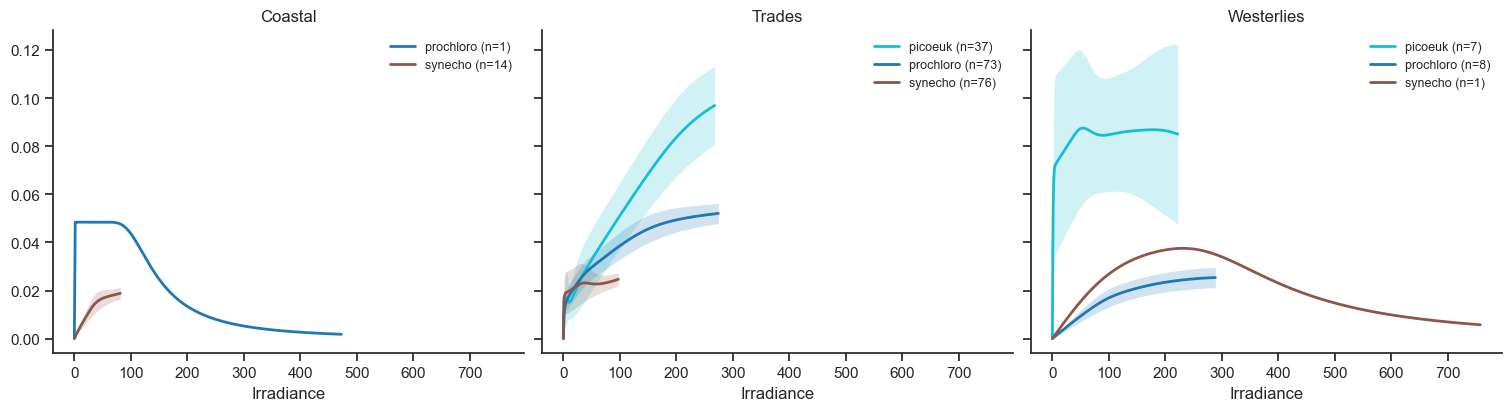

In [101]:
biomes = grouped_pi["biome"].drop_duplicates().tolist()
populations = grouped_pi["pop"].drop_duplicates().tolist()

colors = dict(zip(
    populations,
    plt.cm.tab10(np.linspace(0, 1, len(populations)))
))

ncols = min(3, len(biomes))
nrows = int(np.ceil(len(biomes) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(5 * ncols, 4 * nrows),
    squeeze=False,
    constrained_layout=True,
    sharex = True,
    sharey = True
)

for ax, biome in zip(axes.flat, biomes):

    biome_data = grouped_pi.loc[grouped_pi["biome"].eq(biome)]

    for pop, group in biome_data.groupby("pop"):
        group = group.sort_values("I")

        I = group["I"].to_numpy()
        mean = group["P_mean"].to_numpy()
        lower = group["P_lower"].to_numpy()
        upper = group["P_upper"].to_numpy()
        n = int(group["n_curves"].iloc[0])

        ax.plot(
            I, mean,
            color=colors[pop],
            linewidth=2,
            label=f"{pop} (n={n})"
        )

        if n > 1:
            ax.fill_between(
                I, lower, upper,
                color=colors[pop],
                alpha=0.2,
                linewidth=0
            )

    ax.set_title(biome)
    ax.set_xlabel("Irradiance")
    # ax.set_ylabel("Photosynthetic rate")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9)

for ax in list(axes.flat)[len(biomes):]:
    ax.set_visible(False)

plt.show()

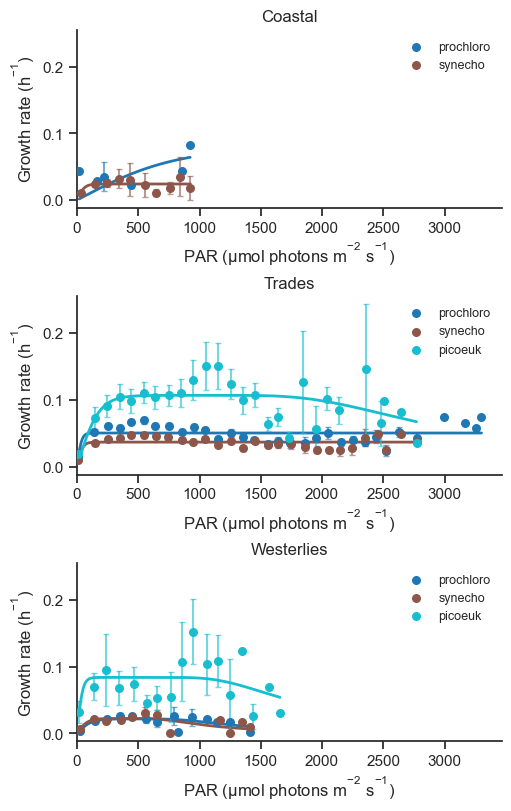

In [118]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

bin_width = 100
min_days_per_bin = 1   # Increase to exclude sparsely sampled bins
pops = ["prochloro", "synecho", "picoeuk"]

# ------------------------------------------------------------
# 1. Extract observations and attach unique daily metadata
# ------------------------------------------------------------
metadata = df[["index_id", "biome", "pop"]].drop_duplicates()

if metadata["index_id"].duplicated().any():
    raise ValueError(
        "Some index_id values have conflicting biome/pop metadata."
    )

# Same observation-deduplication convention as your previous code.
obs = (
    df[["index_id", "hour", "I", "P"]]
    .drop_duplicates()
    .merge(metadata, on="index_id", validate="many_to_one")
)

obs = obs.loc[
    np.isfinite(obs["I"])
    & np.isfinite(obs["P"])
    & obs["I"].ge(0)
    & obs["biome"].notna()
    & obs["pop"].notna()
].copy()

if obs.empty:
    raise ValueError("No valid observations are available.")

# Bin index 0 = [0, 100), 1 = [100, 200), etc.
obs["I_bin"] = np.floor(obs["I"] / bin_width).astype(int)

# ------------------------------------------------------------
# 2. Average within each day/bin, then across days
# ------------------------------------------------------------
daily_bins = (
    obs.groupby(
        ["biome", "pop", "index_id", "I_bin"],
        observed=True,
    )
    .agg(
        I_daily=("I", "mean"),
        P_daily=("P", "mean"),
        n_obs=("P", "size"),
    )
    .reset_index()
)

binned_pi = (
    daily_bins.groupby(
        ["biome", "pop", "I_bin"],
        observed=True,
    )
    .agg(
        I_mean=("I_daily", "mean"),
        P_mean=("P_daily", "mean"),
        P_sd=("P_daily", "std"),
        n_days=("index_id", "nunique"),
        n_obs=("n_obs", "sum"),
    )
    .reset_index()
)

binned_pi["P_se"] = (
    binned_pi["P_sd"] / np.sqrt(binned_pi["n_days"])
)
binned_pi["I_left"] = binned_pi["I_bin"] * bin_width
binned_pi["I_right"] = binned_pi["I_left"] + bin_width

binned_pi = binned_pi.loc[
    binned_pi["n_days"].ge(min_days_per_bin)
].copy()

if binned_pi.empty:
    raise ValueError("No bins meet min_days_per_bin.")

# ------------------------------------------------------------
# 3. Fit one new PI curve per biome/pop to the bin means
# ------------------------------------------------------------
# Wrapper uses parameter order: alpha, Pmax, beta.
def pi_for_fit(I, alpha, Pmax, beta):
    return amirian_pi(I, alpha=alpha, Pmax=Pmax, beta=beta)


fit_rows = []
curve_tables = []

for (biome, pop), group in binned_pi.groupby(
    ["biome", "pop"], observed=True
):
    group = group.sort_values("I_mean")

    x = group["I_mean"].to_numpy(dtype=float)
    y = group["P_mean"].to_numpy(dtype=float)

    result = {
        "biome": biome,
        "pop": pop,
        "alpha": np.nan,
        "Pmax": np.nan,
        "beta": np.nan,
        "n_bins": len(group),
        "status": "not_fitted",
    }

    # More bins than the three fitted parameters.
    if len(group) < 4 or np.unique(x).size < 4:
        result["status"] = "too_few_bins"
        fit_rows.append(result)
        continue

    if y.max() <= 0 or x.max() <= 0:
        result["status"] = "no_positive_response_or_irradiance"
        fit_rows.append(result)
        continue

    # Initial guesses from the observed bin means.
    pmax0 = y.max()
    low = np.flatnonzero(x > 0)[:3]

    alpha0 = (
        np.dot(x[low], y[low]) / np.dot(x[low], x[low])
    )
    alpha0 = max(alpha0, pmax0 / x.max(), 1e-8)

    # Try several inhibition starting values.
    best = None
    errors = []

    for beta0 in (0.0, 0.01 * alpha0, 0.1 * alpha0, alpha0):
        try:
            fitted, _ = curve_fit(
                pi_for_fit,
                x,
                y,
                p0=[alpha0, pmax0, beta0],
                bounds=(
                    [0.0, 1e-12, 0.0],
                    [np.inf, np.inf, np.inf],
                ),
                method="trf",
                x_scale="jac",
                max_nfev=20000,
            )

            residuals = y - pi_for_fit(x, *fitted)
            rss = np.sum(residuals**2)

            if np.isfinite(rss) and (
                best is None or rss < best[0]
            ):
                best = (rss, fitted)

        except (RuntimeError, ValueError, FloatingPointError) as exc:
            errors.append(str(exc))

    if best is None:
        result["status"] = "fit_failed"
        result["message"] = "; ".join(errors)
        fit_rows.append(result)
        continue

    rss, fitted = best
    alpha_fit, pmax_fit, beta_fit = fitted

    result.update({
        "alpha": alpha_fit,
        "Pmax": pmax_fit,
        "beta": beta_fit,
        "rss": rss,
        "status": "fitted",
    })
    fit_rows.append(result)

    # Plot only over the range spanned by retained bin means.
    I_grid = np.linspace(x.min(), x.max(), 300)

    curve_tables.append(pd.DataFrame({
        "biome": biome,
        "pop": pop,
        "I": I_grid,
        "P_fit": pi_for_fit(I_grid, *fitted),
    }))

binned_params = pd.DataFrame(fit_rows)

binned_curves = (
    pd.concat(curve_tables, ignore_index=True)
    if curve_tables
    else pd.DataFrame(columns=["biome", "pop", "I", "P_fit"])
)

# ------------------------------------------------------------
# 4. Plot bin means, SE, and fitted curves
# ------------------------------------------------------------
biomes = binned_pi["biome"].drop_duplicates().tolist()
present_pops = binned_pi["pop"].drop_duplicates().tolist()

populations = (
    [pop for pop in pops if pop in present_pops]
    + [pop for pop in present_pops if pop not in pops]
)

colors = dict(zip(
    populations,
    plt.cm.tab10(np.linspace(0, 1, len(populations))),
))

ncols = min(3, len(biomes))
nrows = int(np.ceil(len(biomes) / ncols))

fig, axes = plt.subplots(
    nrows = ncols,
    # ncols,
    figsize=(5, 8),
    squeeze=False,
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for ax, biome in zip(axes.flat, biomes):
    for pop in populations:
        points = binned_pi.loc[
            binned_pi["biome"].eq(biome)
            & binned_pi["pop"].eq(pop)
        ].sort_values("I_mean")

        if points.empty:
            continue

        # Binned observations
        ax.scatter(
            points["I_mean"],
            points["P_mean"],
            color=colors[pop],
            s=30,
            label=pop,
            zorder=3,
        )

        # SE across daily bin means; undefined for one-day bins.
        with_se = points.loc[points["P_se"].notna()]

        if not with_se.empty:
            ax.errorbar(
                with_se["I_mean"],
                with_se["P_mean"],
                yerr=with_se["P_se"],
                fmt="none",
                ecolor=colors[pop],
                capsize=2,
                alpha=0.6,
                zorder=2,
            )

        # Curve fitted to the bin means
        curve = binned_curves.loc[
            binned_curves["biome"].eq(biome)
            & binned_curves["pop"].eq(pop)
        ].sort_values("I")

        if not curve.empty:
            ax.plot(
                curve["I"],
                curve["P_fit"],
                color=colors[pop],
                linewidth=2,
            )

    ax.set_title(biome)
    ax.set_xlabel(f"PAR (µmol photons {m2} {s1})")
    ax.set_ylabel(f"Growth rate ({h1})")
    ax.tick_params(labelbottom=True, labelleft=True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9)

axes.flat[0].set_xlim(left=0)

for ax in list(axes.flat)[len(biomes):]:
    ax.set_visible(False)

plt.show()

# Useful outputs:
# binned_pi: observed bin means, counts, and SE
# binned_params: fitted parameters and fitting status
# binned_curves: smooth curves fitted to the bin means

### PAR data

In [ ]:
# show integrated PAR Westerlies vs. Trades
df = diel_pi.copy()

# sort by date to get nice lines
df = df.sort_values('cruise_day')

fig, axs = plt.subplots(
    nrows=len(params),
    ncols=1,
    figsize=(4, 8),
    sharex=True,
    constrained_layout=True
)

if len(params) == 1:
    axs = [axs]

for ax, param in zip(axs, params):
    # drop infinities/nans
    df_param = df[['cruise_day', 'pop', param]].replace([np.inf, -np.inf], np.nan).dropna()
    if df_param.empty:
        ax.set_visible(False)
        continue

    for pop in pops:
        sub = df_param[df_param['pop'] == pop]
        if sub.empty:
            continue

        ax.plot(
            sub['date'],
            sub[param],
            marker='o',
            linewidth=1,
            linestyle ='',
            markersize=5,
            color=pop_palette[pop],
            label=pop
        )

    ax.set_ylabel(param_labels[param], fontsize=12)
    ax.tick_params(labelsize=12)

# x-axis label on bottom panel only
axs[-1].set_xlabel('Cruise Day', fontsize=12)


plt.show()

In [67]:
# read in weighted data
pi_df = pd.read_csv('../data/new_pi_data_weight3.csv')
# pair with longhurst data
final_rates_geo = pd.read_csv('../data/final_rates_geo.csv')
# merge with pi data
pi_merged = pi_df.merge(final_rates_geo[['cruise', 'cruise_day', 'pop', 'biome', 'region']])
# plot distributions by biome
pi_30min = pi_merged.loc[pi_merged['time_res'] == '30min'].reset_index(drop = True)
pi_1H = pi_merged.loc[pi_merged['time_res'] == '1H'].reset_index(drop = True)

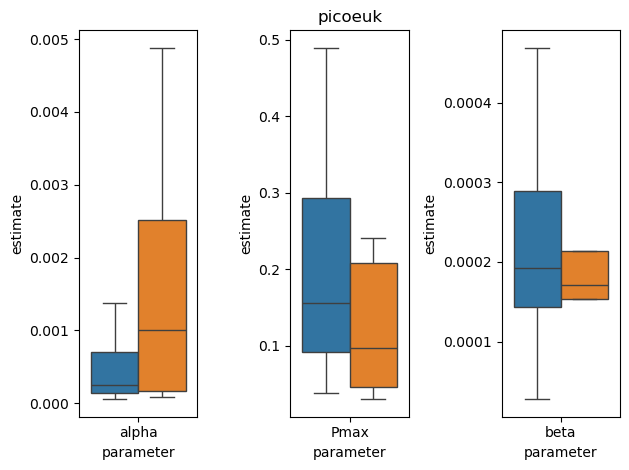

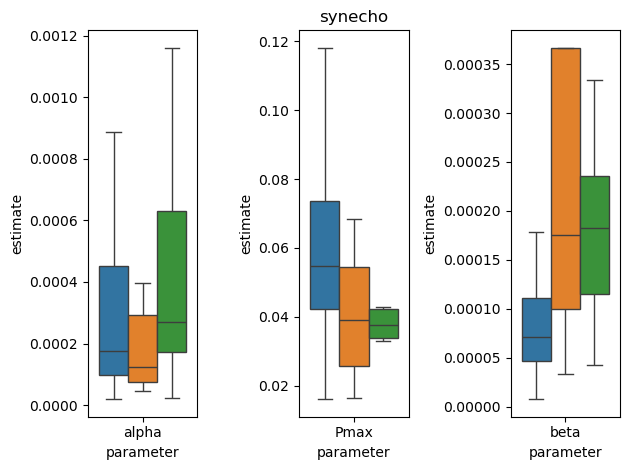

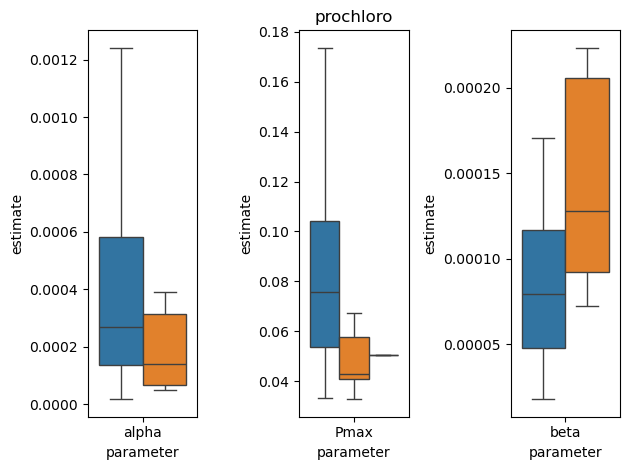

In [3]:
import matplotlib.pyplot as plt
# loop through each population
for pop in pi_30min['pop'].unique():
    pop_df = pi_30min.loc[pi_30min['pop'] == pop]
    fig, axs = plt.subplots(ncols = 3)
    ax_count = 0
    # plot with seaborn- loop through each parameter
    for param in pi_30min['parameter'].unique():
        param_df = pop_df.loc[pop_df['parameter'] == param]
        sns.boxplot(param_df, x = 'parameter', y = 'estimate', hue = 'biome', 
                    showfliers = False, ax= axs[ax_count], legend = False)
        # axs.set_title(pop)
        ax_count +=1
    axs[ax_count-2].set_title(pop)
    plt.tight_layout()

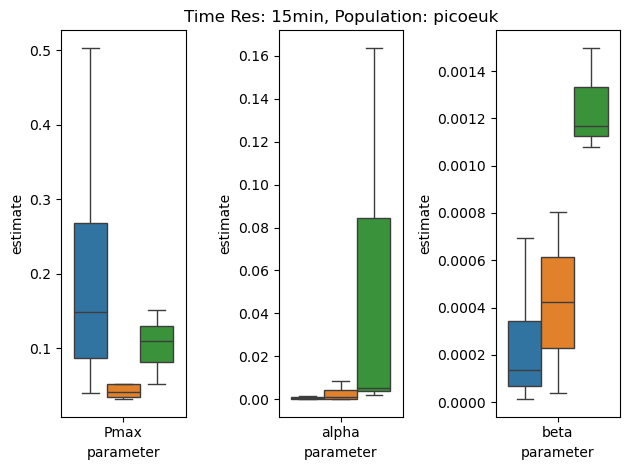

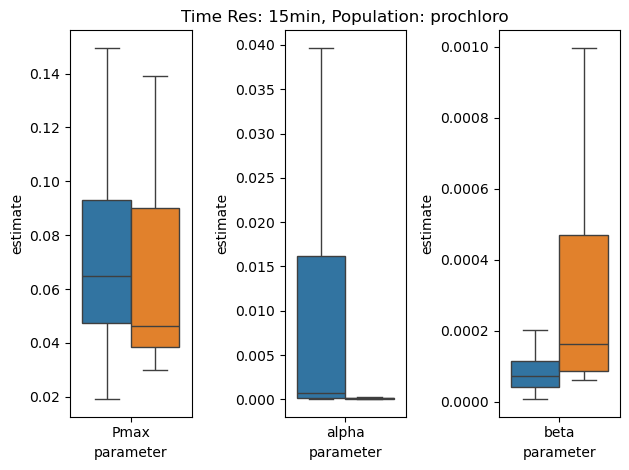

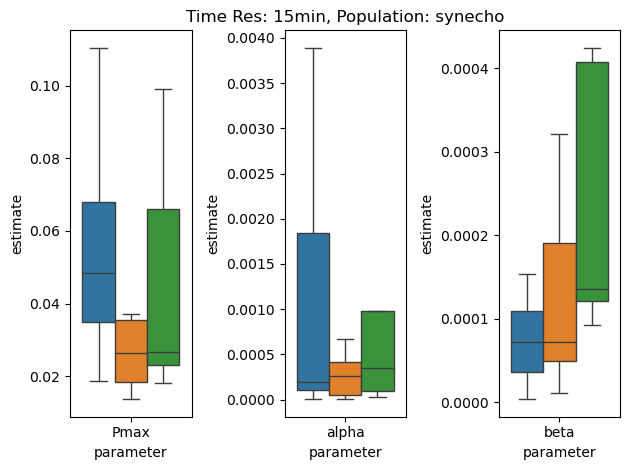

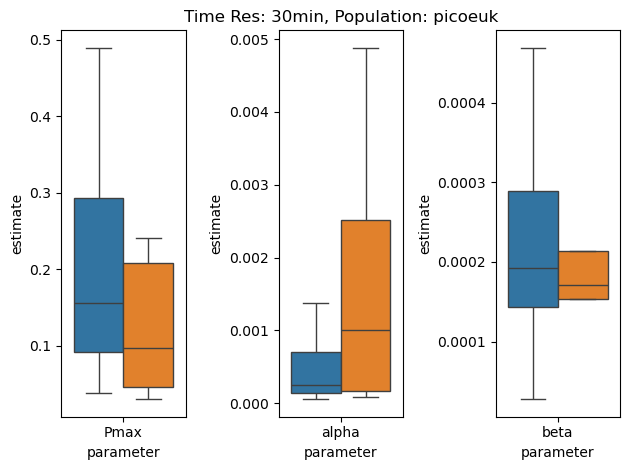

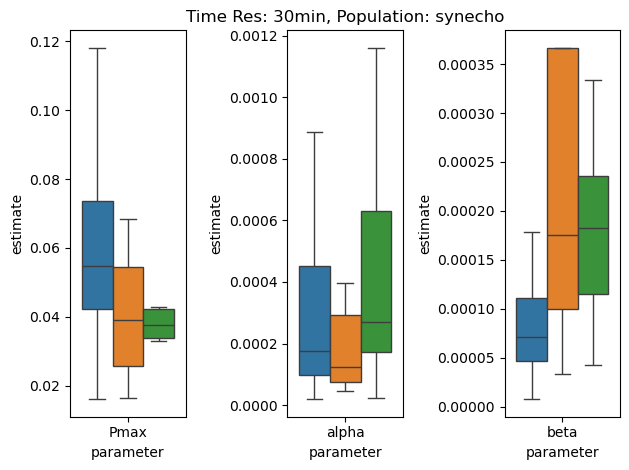

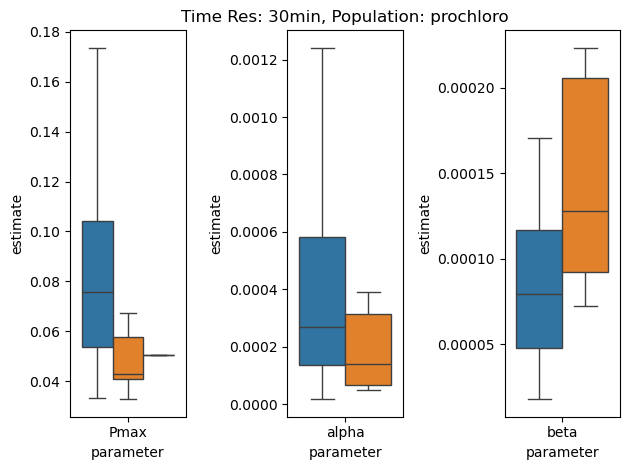

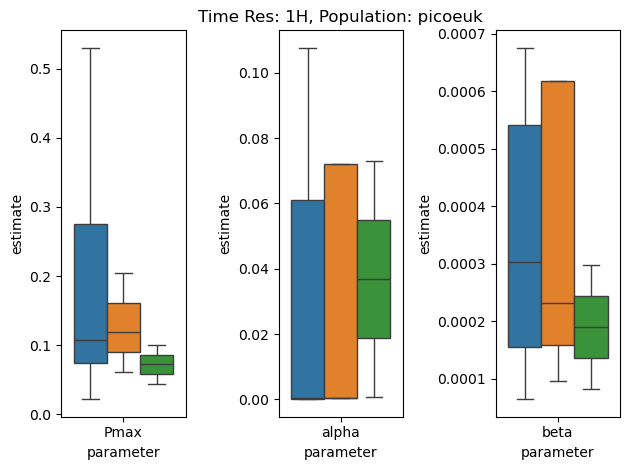

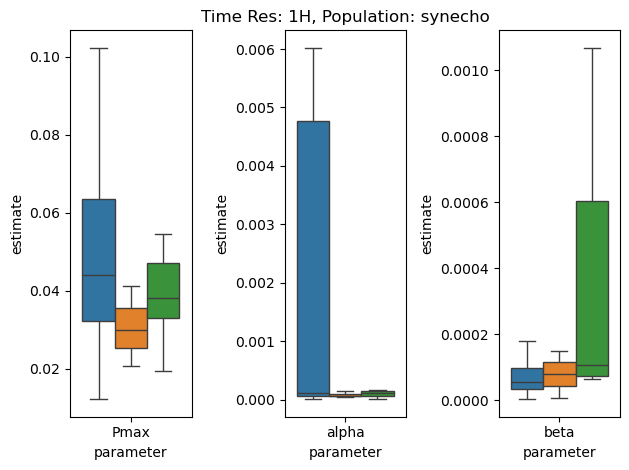

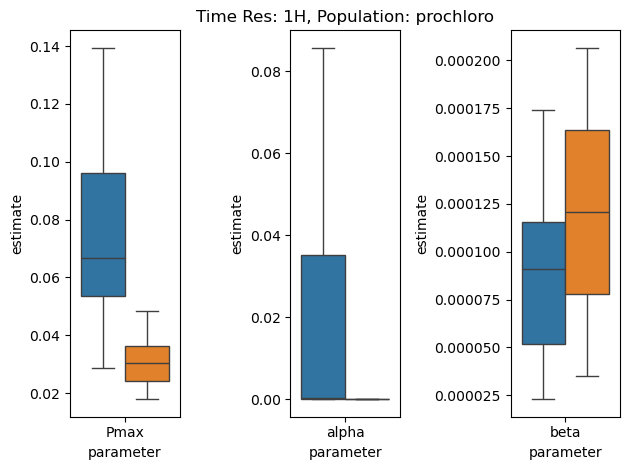

In [4]:
import matplotlib.pyplot as plt
# loop through each time resolution and see how distributions change 
for timeres in pi_merged['time_res'].unique():
    time_df = pi_merged.loc[pi_merged['time_res'] == timeres]
    # loop through each population
    for pop in time_df['pop'].unique():
        pop_df = time_df.loc[time_df['pop'] == pop]
        fig, axs = plt.subplots(ncols = 3)
        ax_count = 0
        # plot with seaborn- loop through each parameter
        for param in pi_merged['parameter'].unique():
            param_df = pop_df.loc[pop_df['parameter'] == param]
            sns.boxplot(param_df, x = 'parameter', y = 'estimate', hue = 'biome', 
                        showfliers = False, ax= axs[ax_count], legend = False)
            # axs.set_title(pop)
            ax_count +=1
        axs[ax_count-2].set_title(f'Time Res: {timeres}, Population: {pop}')
        plt.tight_layout()

In [29]:
## generate PI curve based on these distributions for each population and time resolution
# read in pi label data
all_pi_labs = pd.read_csv('../data/all_pi_labels.csv')
# subset to just the cols we need 
all_pi_sub = all_pi_labs[['cruise', 'cruise_day', 'pop', 'index_id', 'time_res', 'hour', 'P', 'I']]

# merge with parameter data for different time resolutions
# pi_30min_all = pi_30min.merge(all_pi_sub)
# pi_1H_all = pi_1H.merge(all_pi_sub)


### GEnerate PI curves from data

In [51]:
pi_30min_all

,time_res,index_id,cruise,cruise_day,pop,n_obs,parameter,estimate,log_estimate,biome,region,hour,P,I
0,30min,pi-1,FK180310-1,1,picoeuk,16,alpha,0.000363,-7.921604,Trades,NPTG,0.0,0.000000,0.000000
1,30min,pi-1,FK180310-1,1,picoeuk,16,alpha,0.000363,-7.921604,Trades,NPTG,2.0,0.073523,0.000000
2,30min,pi-1,FK180310-1,1,picoeuk,16,alpha,0.000363,-7.921604,Trades,NPTG,2.5,0.067687,122.542684
3,30min,pi-1,FK180310-1,1,picoeuk,16,alpha,0.000363,-7.921604,Trades,NPTG,3.0,0.061851,274.628751
4,30min,pi-1,FK180310-1,1,picoeuk,16,alpha,0.000363,-7.921604,Trades,NPTG,3.5,0.059724,406.501096
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11243,30min,pi-99,KM1513,6,prochloro,18,beta,0.000049,-9.916542,Trades,NPTG,7.0,0.017034,2303.102200
11244,30min,pi-99,KM1513,6,prochloro,18,beta,0.000049,-9.916542,Trades,NPTG,7.5,0.003509,2289.697228
11245,30min,pi-99,KM1513,6,prochloro,18,beta,0.000049,-9.916542,Trades,NPTG,8.0,0.025280,2279.406116
11246,30min,pi-99,KM1513,6,prochloro,18,beta,0.000049,-9.916542,Trades,NPTG,8.5,0.031506,2244.454288


In [58]:
# helper fuctions to generate mohammad's PI curves

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def amirian_pi(I, alpha, Pmax, beta):
    """Amirian double-tanh PI model, with respiration fixed at zero."""
    I = np.asarray(I, dtype=float)
    gamma = np.cosh(1.0)**2

    ratio = np.full_like(I, np.inf)
    np.divide(
        Pmax,
        beta * I,
        out=ratio,
        where=(beta * I > 0)
    )

    saturation = np.tanh(alpha * I / Pmax)
    inhibition = np.tanh(np.minimum(ratio, 100.0)**gamma)

    return Pmax * saturation * inhibition


def reconstruct_daily_pi(df, n_grid=300):
    """
    Reconstruct one PI curve per index_id.

    Returns
    -------
    daily_curves : DataFrame
        Smooth reconstructed curves, with daily metadata.
    daily_params : DataFrame
        One parameter set per index_id, including reconstruction status.
    observations : DataFrame
        Hourly I and P observations without parameter-format duplication.
    """
    names = ["alpha", "Pmax", "beta"]

    # Remove copies of the same daily estimate repeated across hours.
    parameter_rows = (
        df.loc[
            df["parameter"].isin(names),
            ["index_id", "parameter", "estimate"]
        ]
        .drop_duplicates()
    )

    # Do not silently average conflicting estimates.
    if parameter_rows.duplicated(["index_id", "parameter"]).any():
        raise ValueError(
            "Some index_id values have multiple distinct estimates for "
            "the same parameter. Check the grouping or add a draw identifier."
        )

    params = (
        parameter_rows
        .pivot(index="index_id", columns="parameter", values="estimate")
        .reindex(columns=names)
    )

    metadata_cols = [
        "index_id", "cruise", "cruise_day", "pop", "time_res"
    ]
    metadata = df[metadata_cols].drop_duplicates()

    if metadata["index_id"].duplicated().any():
        raise ValueError("index_id does not uniquely identify the daily metadata.")

    observations = (
        df[["index_id", "hour", "I", "P"]]
        .drop_duplicates()
        .sort_values(["index_id", "hour"])
    )

    valid = (
        params.notna().all(axis=1)
        & np.isfinite(params).all(axis=1)
        & params["alpha"].ge(0)
        & params["Pmax"].gt(0)
        & params["beta"].ge(0)
    )

    curve_tables = []

    for index_id, pars in params.loc[valid].iterrows():
        I_max = observations.loc[
            observations["index_id"].eq(index_id), "I"
        ].max()

        if not np.isfinite(I_max) or I_max <= 0:
            continue

        I_grid = np.linspace(0, I_max, n_grid)

        curve_tables.append(pd.DataFrame({
            "index_id": index_id,
            "I": I_grid,
            "P_fit": amirian_pi(
                I_grid,
                alpha=pars["alpha"],
                Pmax=pars["Pmax"],
                beta=pars["beta"]
            )
        }))

    daily_curves = (
        pd.concat(curve_tables, ignore_index=True)
        if curve_tables
        else pd.DataFrame(columns=["index_id", "I", "P_fit"])
    )

    daily_curves = daily_curves.merge(
        metadata, on="index_id", validate="many_to_one"
    )

    daily_params = params.reset_index().merge(
        metadata, on="index_id", validate="one_to_one"
    )

    reconstructed_ids = set(daily_curves["index_id"])

    daily_params["status"] = np.where(
        daily_params["index_id"].isin(reconstructed_ids),
        "reconstructed",
        "missing_or_invalid_parameters_or_irradiance"
    )

    return daily_curves, daily_params, observations

In [63]:
df = pi_30min_all.copy()
daily_curves, daily_params, observations = reconstruct_daily_pi(df)

# Inspect IDs that could not be reconstructed.
skipped = daily_params.loc[
    daily_params["status"] != "reconstructed"
]

# Add biome metadata, which was not included in the previous daily_params table.
metadata = df[["index_id", "biome", "pop"]].drop_duplicates()

if metadata["index_id"].duplicated().any():
    raise ValueError("Some index_id values have conflicting biome/pop metadata.")

# Keep only complete, valid daily parameter sets.
pars = (
    daily_params.loc[
        daily_params["status"].eq("reconstructed"),
        ["index_id", "alpha", "Pmax", "beta"]
    ]
    .merge(metadata, on="index_id", validate="one_to_one")
)

# Maximum observed irradiance for each day.
daily_Imax = df.groupby("index_id")["I"].max()

# Reconstruct all daily curves within each biome/pop group.
group_curve_tables = []

for (biome, pop), group in pars.groupby(["biome", "pop"]):

    # Shared irradiance grid within this group.
    # Using the minimum daily maximum avoids extrapolating beyond
    # any included day's observed maximum irradiance.
    I_max = daily_Imax.reindex(group["index_id"]).min()

    if not np.isfinite(I_max) or I_max <= 0:
        continue

    I_grid = np.linspace(0, I_max, 300)

    curves = np.vstack([
        amirian_pi(
            I_grid,
            alpha=row.alpha,
            Pmax=row.Pmax,
            beta=row.beta
        )
        for row in group.itertuples(index=False)
    ])

    n = curves.shape[0]
    mean_curve = curves.mean(axis=0)

    # SE is undefined if a group contains only one daily curve.
    se_curve = (
        curves.std(axis=0, ddof=1) / np.sqrt(n)
        if n > 1
        else np.full(I_grid.shape, np.nan)
    )

    group_curve_tables.append(pd.DataFrame({
        "biome": biome,
        "pop": pop,
        "I": I_grid,
        "P_mean": mean_curve,
        "P_se": se_curve,
        "P_lower": mean_curve - se_curve,
        "P_upper": mean_curve + se_curve,
        "n_curves": n
    }))

grouped_pi = pd.concat(group_curve_tables, ignore_index=True)

grouped_pi

,biome,pop,I,P_mean,P_se,P_lower,P_upper,n_curves
0,Coastal,synecho,0.000000,0.000000,0.000000,0.000000,0.000000,10
1,Coastal,synecho,1.580610,0.000757,0.000312,0.000445,0.001069,10
2,Coastal,synecho,3.161221,0.001471,0.000585,0.000886,0.002056,10
3,Coastal,synecho,4.741831,0.002119,0.000798,0.001322,0.002917,10
4,Coastal,synecho,6.322442,0.002700,0.000951,0.001749,0.003650,10
...,...,...,...,...,...,...,...,...
2095,Westerlies,synecho,854.120299,0.017786,0.006877,0.010909,0.024663,3
2096,Westerlies,synecho,857.015622,0.017726,0.006867,0.010859,0.024592,3
2097,Westerlies,synecho,859.910945,0.017665,0.006856,0.010809,0.024522,3
2098,Westerlies,synecho,862.806268,0.017604,0.006846,0.010759,0.024450,3


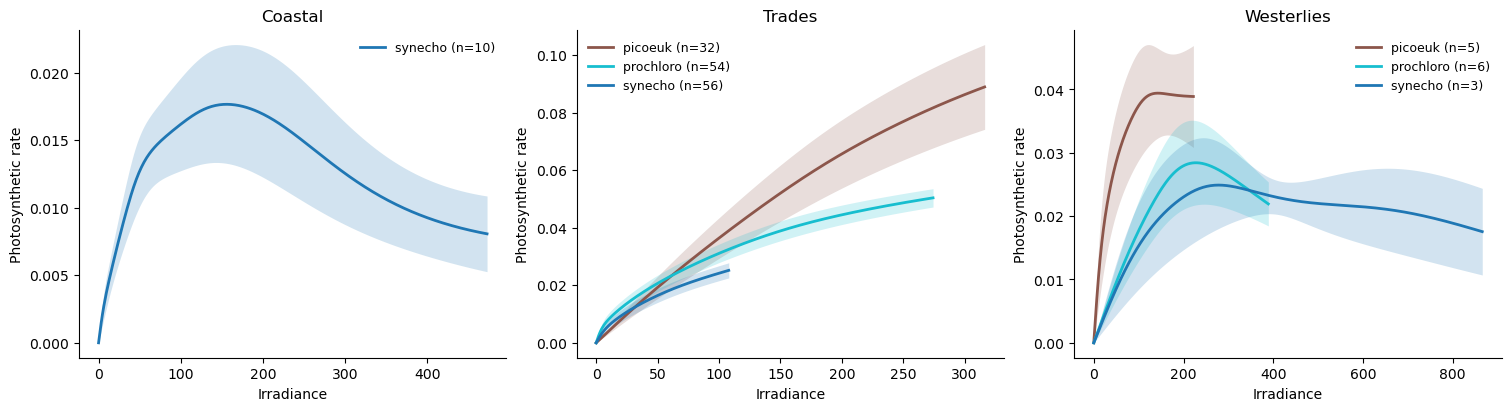

In [64]:
biomes = grouped_pi["biome"].drop_duplicates().tolist()
populations = grouped_pi["pop"].drop_duplicates().tolist()

colors = dict(zip(
    populations,
    plt.cm.tab10(np.linspace(0, 1, len(populations)))
))

ncols = min(3, len(biomes))
nrows = int(np.ceil(len(biomes) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(5 * ncols, 4 * nrows),
    squeeze=False,
    constrained_layout=True
)

for ax, biome in zip(axes.flat, biomes):

    biome_data = grouped_pi.loc[grouped_pi["biome"].eq(biome)]

    for pop, group in biome_data.groupby("pop"):
        group = group.sort_values("I")

        I = group["I"].to_numpy()
        mean = group["P_mean"].to_numpy()
        lower = group["P_lower"].to_numpy()
        upper = group["P_upper"].to_numpy()
        n = int(group["n_curves"].iloc[0])

        ax.plot(
            I, mean,
            color=colors[pop],
            linewidth=2,
            label=f"{pop} (n={n})"
        )

        if n > 1:
            ax.fill_between(
                I, lower, upper,
                color=colors[pop],
                alpha=0.2,
                linewidth=0
            )

    ax.set_title(biome)
    ax.set_xlabel("Irradiance")
    ax.set_ylabel("Photosynthetic rate")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9)

for ax in list(axes.flat)[len(biomes):]:
    ax.set_visible(False)

plt.show()

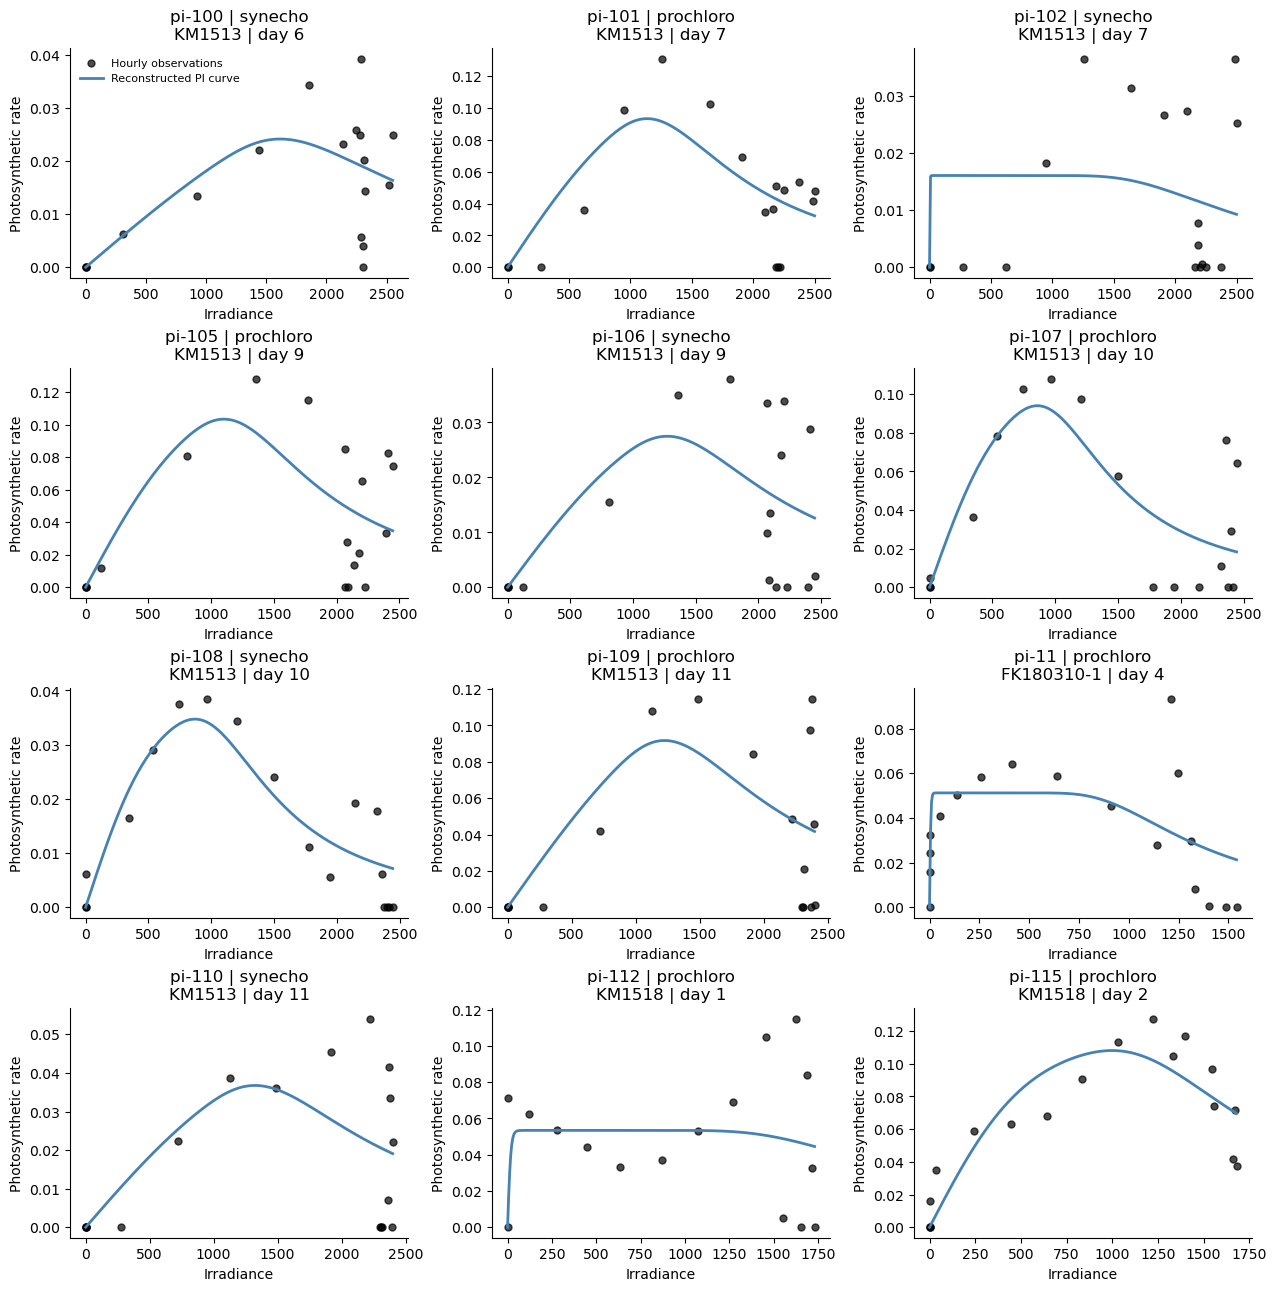

In [60]:
ids_to_plot = daily_curves["index_id"].drop_duplicates().head(12).tolist()

ncols = 3
nrows = int(np.ceil(len(ids_to_plot) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.2 * ncols, 3.2 * nrows),
    squeeze=False,
    constrained_layout=True
)

for ax, index_id in zip(axes.flat, ids_to_plot):
    curve = daily_curves.loc[
        daily_curves["index_id"].eq(index_id)
    ]

    obs = observations.loc[
        observations["index_id"].eq(index_id)
    ]

    info = curve.iloc[0]

    ax.scatter(
        obs["I"], obs["P"],
        s=25, alpha=0.7, color="black",
        label="Hourly observations"
    )

    ax.plot(
        curve["I"], curve["P_fit"],
        color="steelblue", linewidth=2,
        label="Reconstructed PI curve"
    )

    ax.set_title(
        f"{index_id} | {info['pop']}\n"
        f"{info['cruise']} | day {info['cruise_day']}"
    )

    ax.set_xlabel("Irradiance")
    ax.set_ylabel("Photosynthetic rate")
    ax.spines[["top", "right"]].set_visible(False)

for ax in list(axes.flat)[len(ids_to_plot):]:
    ax.set_visible(False)

axes.flat[0].legend(frameon=False, fontsize=8)
plt.show()

In [54]:
# Choose the irradiance range for reconstruction.
df = pi_30min_all.copy()
I_grid = np.linspace(0, df["I"].max(), 500)

summary, curves, params = reconstruct_pi(
    df,
    I_grid,
    id_cols=["I", "P"]
)

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.fill_between(
    summary["I"].to_numpy(),
    summary["P_lower"].to_numpy(),
    summary["P_upper"].to_numpy(),
    color="steelblue",
    alpha=0.25,
    label="Mean ± 1 SE"
)

ax.plot(
    summary["I"],
    summary["P_mean"],
    color="steelblue",
    linewidth=2,
    label="Mean reconstructed PI curve"
)

# Optional: show observations, removing repeats from the long-format table.
observations = df[["I", "P"]].drop_duplicates()

ax.scatter(
    observations["I"],
    observations["P"],
    color="black",
    s=20,
    alpha=0.5,
    label="Observed P",
    zorder=3
)

ax.set(
    xlabel="Irradiance",
    ylabel="Photosynthetic rate"
)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

ValueError: Multiple estimates occur for the same identifier and parameter. Use id_cols that uniquely identify each fitted curve or draw.

### Check if growth rate data makes sense

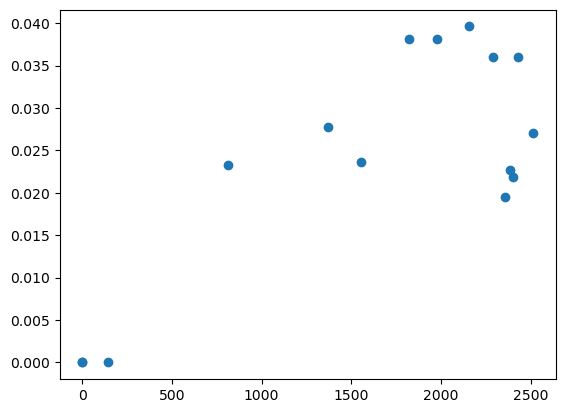

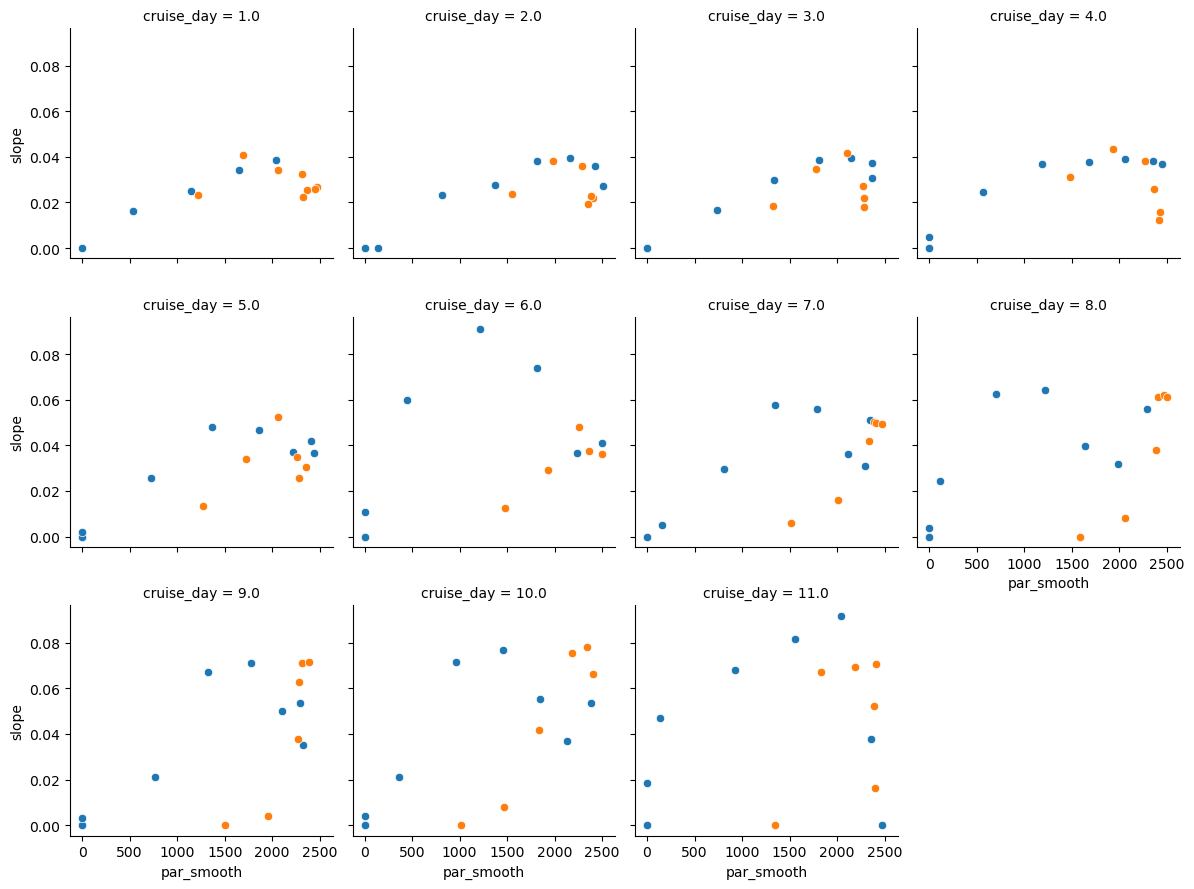

In [50]:
growth_1H = pd.read_csv('../data/clean_growth_1H.csv')
diel_test = growth_1H.loc[(growth_1H['cruise'] == 'KM1513') & 
                          (growth_1H['pop'] == 'prochloro')]

day2_test = diel_test.loc[diel_test['cruise_day'] == 2]
plt.scatter(day2_test['par_smooth'], day2_test['slope'])
# make facetplot
g = sns.FacetGrid(diel_test, col = 'cruise_day', hue = 'day_half', col_wrap = 4)
g.map(sns.scatterplot, 'par_smooth', 'slope')

In [48]:
diel_test.loc[diel_test['cruise_day'] == 2]

,Unnamed: 0,cruise_day,pop,time,hour,slope,yint,mld,par_smooth,int_par,round_par,cruise,season,halfway_hour,day_half
878,13,2.0,prochloro,2015-07-26 09:00:00,0.0,0.000000,0.000000,31.666667,0.000000,0.000000e+00,0.0,KM1513,Summer,9.0,first
879,14,2.0,prochloro,2015-07-26 10:00:00,1.0,0.000000,0.038798,31.666667,0.000000,0.000000e+00,0.0,KM1513,Summer,9.0,first
880,15,2.0,prochloro,2015-07-26 15:00:00,2.0,0.000000,-0.056436,31.666667,143.650977,5.171435e+05,150.0,KM1513,Summer,9.0,first
881,16,2.0,prochloro,2015-07-26 16:00:00,3.0,0.023245,-0.246103,31.666667,811.827317,3.439722e+06,800.0,KM1513,Summer,9.0,first
882,17,2.0,prochloro,2015-07-26 17:00:00,4.0,0.027708,-0.263957,31.666667,1370.117155,8.372144e+06,1350.0,KM1513,Summer,9.0,first
883,18,2.0,prochloro,2015-07-26 18:00:00,5.0,0.038108,-0.315957,31.666667,1818.520490,1.491882e+07,1800.0,KM1513,Summer,9.0,first
884,19,2.0,prochloro,2015-07-26 19:00:00,6.0,0.039605,-0.324936,31.666667,2157.037322,2.268415e+07,2150.0,KM1513,Summer,9.0,first
885,20,2.0,prochloro,2015-07-26 20:00:00,7.0,0.035969,-0.299484,31.666667,2425.861573,3.141725e+07,2450.0,KM1513,Summer,9.0,first
886,21,2.0,prochloro,2015-07-26 21:00:00,8.0,0.027003,-0.227760,31.666667,2512.161436,4.046103e+07,2500.0,KM1513,Summer,9.0,first
887,22,2.0,prochloro,2015-07-26 22:00:00,9.0,0.021804,-0.180968,31.666667,2399.089206,4.909776e+07,2400.0,KM1513,Summer,9.0,second


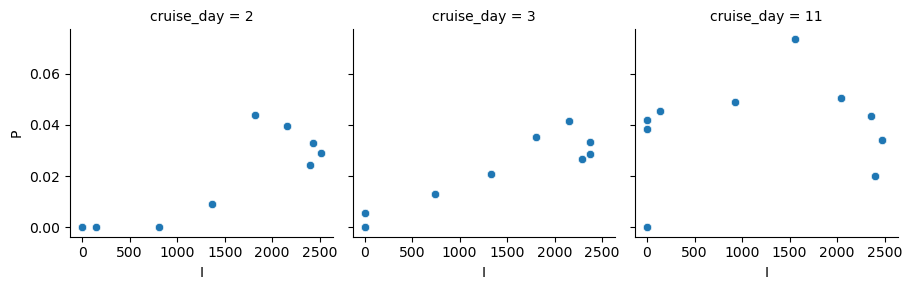

In [39]:
diel_pi_test = pi_1H_all.loc[(pi_1H_all['cruise'] == 'KM1513') & 
                          (pi_1H_all['pop'] == 'prochloro')]

# make facetplot
g = sns.FacetGrid(diel_pi_test, col = 'cruise_day', col_wrap = 4)
g.map(sns.scatterplot, 'I', 'P')

In [47]:
day2_test

,Unnamed: 0,cruise_day,pop,time,hour,slope,yint,mld,par_smooth,int_par,round_par,cruise,season,halfway_hour,day_half
878,13,2.0,prochloro,2015-07-26 09:00:00,0.0,0.000000,0.000000,31.666667,0.000000,0.000000e+00,0.0,KM1513,Summer,9.0,first
879,14,2.0,prochloro,2015-07-26 10:00:00,1.0,0.000000,0.038798,31.666667,0.000000,0.000000e+00,0.0,KM1513,Summer,9.0,first
880,15,2.0,prochloro,2015-07-26 15:00:00,2.0,0.000000,-0.056436,31.666667,143.650977,5.171435e+05,150.0,KM1513,Summer,9.0,first
881,16,2.0,prochloro,2015-07-26 16:00:00,3.0,0.023245,-0.246103,31.666667,811.827317,3.439722e+06,800.0,KM1513,Summer,9.0,first
882,17,2.0,prochloro,2015-07-26 17:00:00,4.0,0.027708,-0.263957,31.666667,1370.117155,8.372144e+06,1350.0,KM1513,Summer,9.0,first
883,18,2.0,prochloro,2015-07-26 18:00:00,5.0,0.038108,-0.315957,31.666667,1818.520490,1.491882e+07,1800.0,KM1513,Summer,9.0,first
884,19,2.0,prochloro,2015-07-26 19:00:00,6.0,0.039605,-0.324936,31.666667,2157.037322,2.268415e+07,2150.0,KM1513,Summer,9.0,first
885,20,2.0,prochloro,2015-07-26 20:00:00,7.0,0.035969,-0.299484,31.666667,2425.861573,3.141725e+07,2450.0,KM1513,Summer,9.0,first
886,21,2.0,prochloro,2015-07-26 21:00:00,8.0,0.027003,-0.227760,31.666667,2512.161436,4.046103e+07,2500.0,KM1513,Summer,9.0,first
887,22,2.0,prochloro,2015-07-26 22:00:00,9.0,0.021804,-0.180968,31.666667,2399.089206,4.909776e+07,2400.0,KM1513,Summer,9.0,second


In [46]:
diel_pi_test.loc[diel_pi_test['cruise_day']==2]

,time_res,index_id,cruise,cruise_day,pop,n_obs,parameter,estimate,log_estimate,biome,region,hour,P,I
3601,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,0.0,0.000000,0.000000
3602,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,1.0,0.000000,0.000000
3603,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,2.0,0.000000,143.650977
3604,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,3.0,0.000000,811.827317
3605,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,4.0,0.009087,1370.117155
3606,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,5.0,0.043852,1818.520490
3607,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,6.0,0.039594,2157.037322
3608,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,7.0,0.032752,2425.861573
3609,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,8.0,0.028921,2512.161436
3610,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,9.0,0.024239,2399.089206
